# Human Activity Recognition: Why Are Volunteers 9 and 10 Harder?

**AAI 501, University of San Diego** | Francois Lubin, Lernik Avetisyan, Alex Denbaugh

Notebook 2 found that accuracy depends more on **who** is wearing the phone than on which model
is used: every model scored about 83-90% on test volunteers 9 and 10, but 95-99% on most others.
This notebook investigates why (focus issues a and b in the proposal):

1. Which activities do volunteers 9 and 10 get wrong, compared with everyone else?
2. Is it a shortage of data, or something about the data itself?
3. Are the errors scattered, or do they happen in runs at particular moments?
4. What is different about the misclassified windows? We focus on the **gravity features**,
   which describe how the phone is tilted (its orientation), because they dominate the
   sitting vs. standing decision (Notebook 2, Section 3.1).

We reuse the two best tuned models from Notebook 2: the SVM (`C=100`, `gamma=0.0001`) and
logistic regression (`C=0.1`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
DATA_DIR = Path("data") / "UCI HAR Dataset"
assert DATA_DIR.exists(), f"Dataset not found at {DATA_DIR.resolve()}"

## 1. Load the data and refit the tuned models

In [2]:
def load_feature_names(data_dir):
    feats = pd.read_csv(data_dir / "features.txt", sep=r"\s+", header=None,
                        names=["idx", "name"])
    return [f"{name}__{idx}" for idx, name in zip(feats["idx"], feats["name"])]


def load_split(data_dir, split, feature_names):
    folder = data_dir / split
    X = pd.read_csv(folder / f"X_{split}.txt", sep=r"\s+", header=None, names=feature_names)
    y = pd.read_csv(folder / f"y_{split}.txt", header=None).iloc[:, 0]
    subject = pd.read_csv(folder / f"subject_{split}.txt", header=None).iloc[:, 0]
    return X, y.rename("label"), subject.rename("subject")


feature_names = load_feature_names(DATA_DIR)
X_train, y_train, subj_train = load_split(DATA_DIR, "train", feature_names)
X_test, y_test, subj_test = load_split(DATA_DIR, "test", feature_names)

SHORT = {1: "Walk", 2: "Upstairs", 3: "Downstairs", 4: "Sit", 5: "Stand", 6: "Lay"}
LABELS = list(SHORT)

svm = make_pipeline(StandardScaler(),
                    SVC(C=100, gamma=1e-4, random_state=RANDOM_STATE)).fit(X_train, y_train)
lr = make_pipeline(StandardScaler(),
                   LogisticRegression(C=0.1, max_iter=3000,
                                      random_state=RANDOM_STATE)).fit(X_train, y_train)
pred_svm = svm.predict(X_test)
pred_lr = lr.predict(X_test)
prob_true = lr.predict_proba(X_test)[np.arange(len(y_test)), y_test.values - 1]

print(f"Overall test accuracy: SVM {np.mean(pred_svm == y_test):.4f}, "
      f"LR {np.mean(pred_lr == y_test):.4f}")

Overall test accuracy: SVM 0.9562, LR 0.9498


## 2. Accuracy, confidence, and amount of data per test volunteer

*Confidence* is the probability logistic regression gives to the **correct** activity,
averaged over the volunteer's windows. Low values mean the model is unsure about that person,
even when it is right.

In [3]:
test_df = pd.DataFrame({"subject": subj_test, "label": y_test,
                        "svm_ok": pred_svm == y_test.values,
                        "lr_ok": pred_lr == y_test.values, "conf": prob_true})
per_vol = test_df.groupby("subject").agg(
    windows=("label", "size"), svm_acc=("svm_ok", "mean"), lr_acc=("lr_ok", "mean"),
    confidence=("conf", "mean"))
counts = pd.crosstab(test_df["subject"], test_df["label"]).rename(columns=SHORT)
per_vol = per_vol.join(counts).sort_values("svm_acc")
per_vol.index.name = "Test volunteer"
per_vol.style.format({"svm_acc": "{:.1%}", "lr_acc": "{:.1%}", "confidence": "{:.2f}"}) \
    .background_gradient(subset=["svm_acc", "confidence"], cmap="RdYlGn")

,windows,svm_acc,lr_acc,confidence,Walk,Upstairs,Downstairs,Sit,Stand,Lay
Test volunteer,,,,,,,,,,
10,294,89.5%,82.7%,0.80,53,47,38,54,44,58
9,288,89.6%,89.6%,0.87,52,49,42,50,45,50
20,354,94.9%,95.2%,0.93,51,51,45,66,73,68
4,317,95.9%,95.6%,0.93,60,52,45,50,56,54
12,320,96.6%,95.3%,0.92,50,52,46,51,61,60
18,364,97.0%,97.0%,0.94,56,58,55,57,73,65
2,302,98.0%,98.3%,0.97,59,48,47,46,54,48
24,381,98.7%,99.7%,0.98,58,59,55,68,69,72
13,327,98.8%,98.8%,0.98,57,55,47,49,57,62


Volunteers 9 and 10 are at the bottom on both accuracy and confidence. They do **not** have
unusually little data: each has 38-58 windows per activity, similar to everyone else. So the
problem is in *what* their data looks like, not *how much* there is.

## 3. Which activities go wrong?

Confusion matrices show, for each true activity (rows), the percentage of windows predicted as
each activity (columns). We compare volunteers 9 and 10 with the other seven test volunteers
pooled together (SVM predictions).

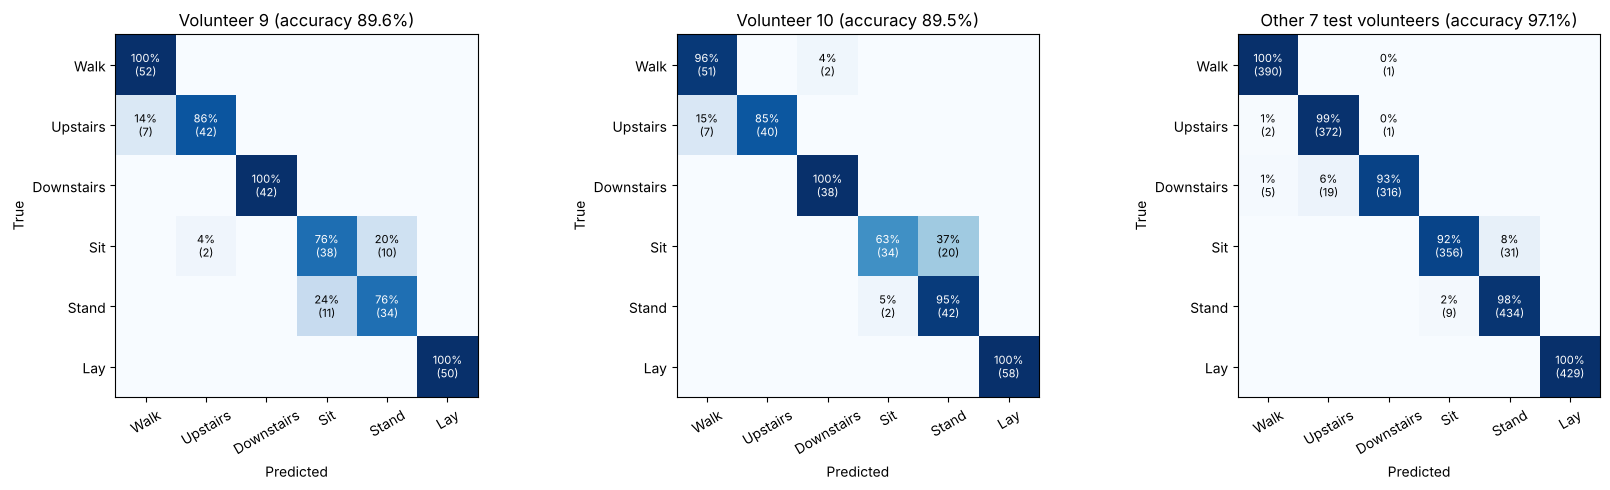

In [4]:
groups = {"Volunteer 9": subj_test.values == 9,
          "Volunteer 10": subj_test.values == 10,
          "Other 7 test volunteers": ~np.isin(subj_test.values, [9, 10])}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (title, mask) in zip(axes, groups.items()):
    cm = confusion_matrix(y_test[mask], pred_svm[mask], labels=LABELS)
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(6):
        for j in range(6):
            if cm[i, j]:
                ax.text(j, i, f"{pct[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center",
                        fontsize=8, color="white" if pct[i, j] > 0.5 else "black")
    ax.set_xticks(range(6), SHORT.values(), rotation=30)
    ax.set_yticks(range(6), SHORT.values())
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"{title} (accuracy {np.mean(pred_svm[mask] == y_test[mask]):.1%})")
plt.tight_layout()
plt.show()

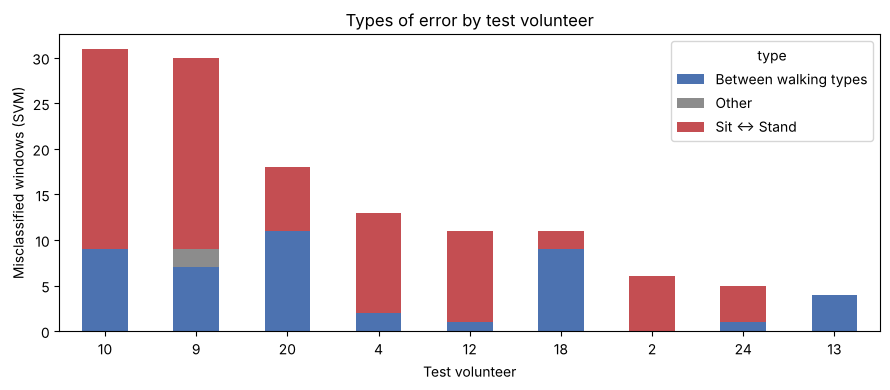

type,Between walking types,Other,Sit <-> Stand,Total errors
Test volunteer,,,,
10,9,0,22,31
9,7,2,21,30
20,11,0,7,18
4,2,0,11,13
12,1,0,10,11
18,9,0,2,11
2,0,0,6,6
24,1,0,4,5
13,4,0,0,4


In [5]:
def error_type(true, pred):
    if true == pred:
        return None
    if {true, pred} <= {4, 5}:
        return "Sit <-> Stand"
    if {true, pred} <= {1, 2, 3}:
        return "Between walking types"
    return "Other"

err = pd.DataFrame({"subject": subj_test, "type": [error_type(t, p) for t, p in
                                                    zip(y_test, pred_svm)]}).dropna()
err_table = pd.crosstab(err["subject"], err["type"])
err_table["Total errors"] = err_table.sum(axis=1)
err_table = err_table.sort_values("Total errors", ascending=False)
err_table.index.name = "Test volunteer"

ax = err_table.drop(columns="Total errors").plot.bar(
    stacked=True, figsize=(9, 4), rot=0, color=["#4C72B0", "#8C8C8C", "#C44E52"])
ax.set_ylabel("Misclassified windows (SVM)")
ax.set_title("Types of error by test volunteer")
plt.tight_layout()
plt.show()
err_table

**Two kinds of trouble.**

- **Sitting vs. standing** is the main problem for both. Volunteer 10's errors are almost all
  one-directional: sitting predicted as standing. Volunteer 9's go both ways.
- **Upstairs predicted as flat walking** adds 7 errors each, a pattern most other volunteers
  do not show (their walking errors are mostly downstairs vs. upstairs).

## 4. Are the errors scattered or clustered in time?

Each window is 2.56 seconds long and overlaps the next by 50%. If the files store windows in
recording order, the second half of one window's raw signal should equal the first half of the
next. We check this with the raw accelerometer signal in `Inertial Signals`. Where the overlap
breaks, a new recording segment starts.

In [6]:
raw_acc_x = np.loadtxt(DATA_DIR / "test" / "Inertial Signals" / "total_acc_x_test.txt")
same_run = np.r_[False, [np.allclose(raw_acc_x[i - 1, 64:], raw_acc_x[i, :64], atol=1e-6)
                         for i in range(1, len(raw_acc_x))]]
pairs = (subj_test.values[1:] == subj_test.values[:-1]) & (y_test.values[1:] == y_test.values[:-1])
print(f"{same_run[1:][pairs].mean():.1%} of neighbouring windows (same person, same activity) "
      "overlap exactly, so the files are in recording order; the rest are segment boundaries.")

95.2% of neighbouring windows (same person, same activity) overlap exactly, so the files are in recording order; the rest are segment boundaries.


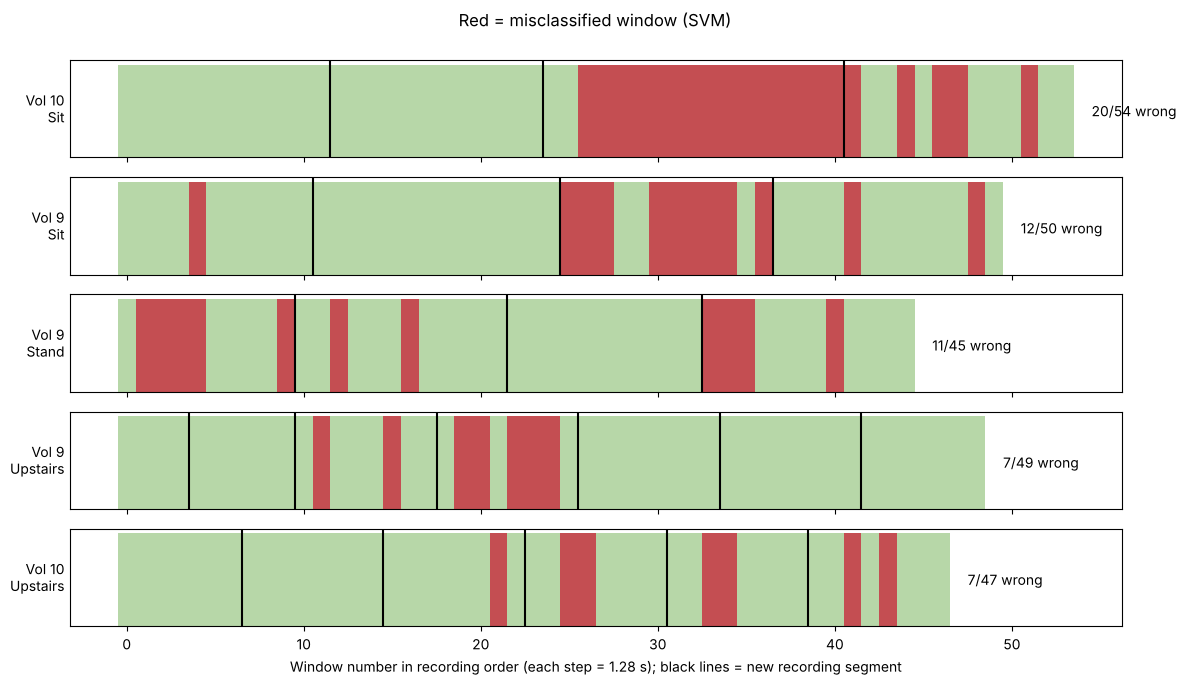

In [7]:
cases = [(10, 4), (9, 4), (9, 5), (9, 2), (10, 2)]
fig, axes = plt.subplots(len(cases), 1, figsize=(12, 1.2 * len(cases) + 0.8), sharex=True)
for ax, (vol, act) in zip(axes, cases):
    idx = np.where((subj_test.values == vol) & (y_test.values == act))[0]
    wrong = pred_svm[idx] != act
    ax.bar(range(len(idx)), np.ones(len(idx)), width=1.0,
           color=np.where(wrong, "#C44E52", "#B7D7A8"))
    for k, i in enumerate(idx):
        if k > 0 and not same_run[i]:
            ax.axvline(k - 0.5, color="black", lw=1.5)
    ax.set_yticks([])
    ax.set_ylabel(f"Vol {vol}\n{SHORT[act]}", rotation=0, ha="right", va="center")
    ax.text(len(idx) + 0.5, 0.5, f"{wrong.sum()}/{len(idx)} wrong", va="center")
axes[-1].set_xlabel("Window number in recording order (each step = 1.28 s); "
                    "black lines = new recording segment")
fig.suptitle("Red = misclassified window (SVM)", y=1.0)
plt.tight_layout()
plt.show()

**Volunteer 10's sitting errors are mostly one continuous run:** 16 windows in a row (about
20 seconds), starting partway through the third sitting segment and running just past the next
segment boundary, followed by a few scattered errors. The first two sitting segments are
classified perfectly. That points to something that changed during that period, such as the
person shifting position or the phone moving on the waist, rather than a general difficulty
with this person.

Volunteer 9's sitting and standing errors are spread across several segments, which suggests a
more general similarity between their sitting and standing.

## 5. What is different about the misclassified windows? Phone orientation

The gravity features measure which way gravity points relative to the phone, in other words how
the phone (and the body at the waist) is tilted. Sitting and standing differ mainly in this tilt.

In [8]:
GRAV = ["tGravityAcc-mean()-X__41", "tGravityAcc-mean()-Y__42", "tGravityAcc-mean()-Z__43",
        "angle(X,gravityMean)__559", "angle(Y,gravityMean)__560", "angle(Z,gravityMean)__561"]

def med(mask, X=X_test):
    return X.loc[mask, GRAV].median()

v10_sit = (subj_test.values == 10) & (y_test.values == 4)
compare = pd.DataFrame({
    "All training: Sit": med(y_train.values == 4, X_train),
    "All training: Stand": med(y_train.values == 5, X_train),
    "Vol 10 Sit, correct": med(v10_sit & (pred_svm == 4)),
    "Vol 10 Sit, wrong": med(v10_sit & (pred_svm != 4)),
    "Vol 10 Stand": med((subj_test.values == 10) & (y_test.values == 5)),
    "Vol 9 Sit": med((subj_test.values == 9) & (y_test.values == 4)),
    "Vol 9 Stand": med((subj_test.values == 9) & (y_test.values == 5)),
})
compare.index = [c.rsplit("__", 1)[0] for c in compare.index]
compare.style.format("{:.2f}").set_caption("Median gravity feature values")

,All training: Sit,All training: Stand,"Vol 10 Sit, correct","Vol 10 Sit, wrong",Vol 10 Stand,Vol 9 Sit,Vol 9 Stand
tGravityAcc-mean()-X,0.93,0.95,0.89,0.68,0.96,0.96,0.96
tGravityAcc-mean()-Y,0.09,-0.19,0.27,-0.57,-0.19,0.01,-0.00
tGravityAcc-mean()-Z,0.20,0.00,0.13,0.33,0.07,0.01,-0.10
"angle(X,gravityMean)",-0.74,-0.79,-0.68,-0.33,-0.81,-0.86,-0.86
"angle(Y,gravityMean)",0.02,0.21,-0.11,0.49,0.22,0.07,0.09
"angle(Z,gravityMean)",-0.12,0.02,-0.07,-0.21,-0.02,0.02,0.09


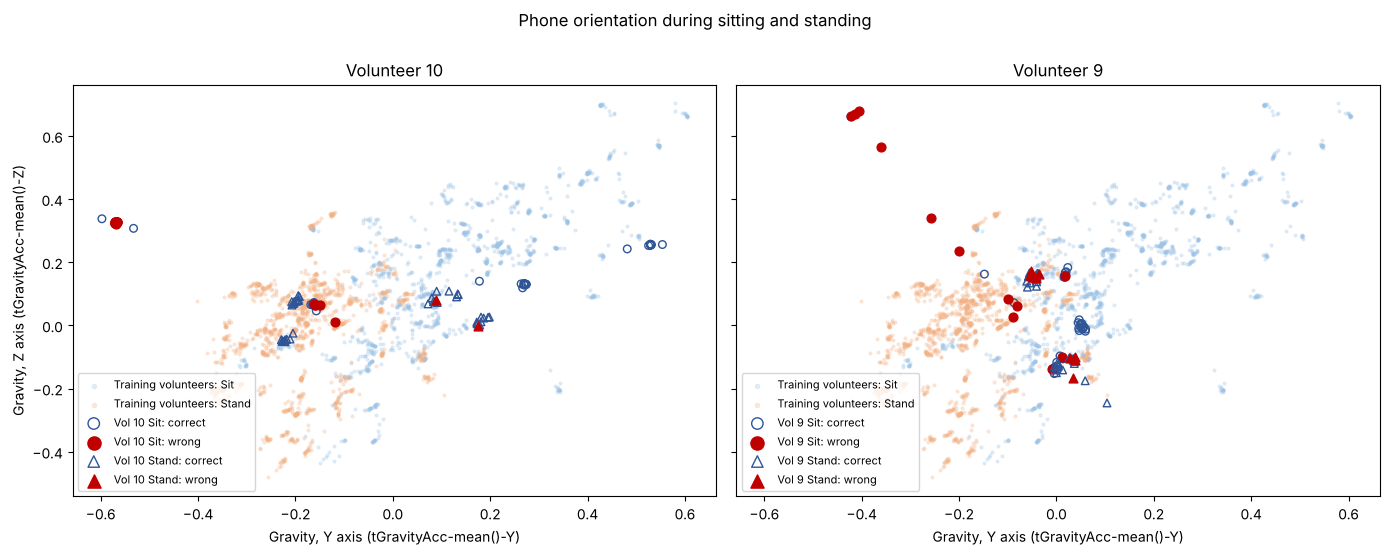

In [9]:
fx, fy = "tGravityAcc-mean()-Y__42", "tGravityAcc-mean()-Z__43"
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, vol in zip(axes, [10, 9]):
    for act, color in [(4, "#9DC3E6"), (5, "#F4B183")]:
        m = y_train.values == act
        ax.scatter(X_train.loc[m, fx], X_train.loc[m, fy], s=4, alpha=0.25, color=color,
                   label=f"Training volunteers: {SHORT[act]}")
    for act, marker in [(4, "o"), (5, "^")]:
        m = (subj_test.values == vol) & (y_test.values == act)
        ok = m & (pred_svm == y_test.values)
        bad = m & (pred_svm != y_test.values)
        ax.scatter(X_test.loc[ok, fx], X_test.loc[ok, fy], s=30, marker=marker,
                   facecolor="none", edgecolor="#2F5597",
                   label=f"Vol {vol} {SHORT[act]}: correct")
        ax.scatter(X_test.loc[bad, fx], X_test.loc[bad, fy], s=40, marker=marker,
                   color="#C00000", label=f"Vol {vol} {SHORT[act]}: wrong")
    ax.set_title(f"Volunteer {vol}")
    ax.set_xlabel("Gravity, Y axis (tGravityAcc-mean()-Y)")
    ax.legend(fontsize=8, loc="lower left", markerscale=1.5)
axes[0].set_ylabel("Gravity, Z axis (tGravityAcc-mean()-Z)")
fig.suptitle("Phone orientation during sitting and standing", y=1.0)
plt.tight_layout()
plt.show()

**Volunteer 10.** In the misclassified windows, the Y-axis gravity value is about -0.57,
compared with about +0.27 for this person's correctly classified sitting. In the scatter plot,
most of those windows fall in the upper-left corner, where there are almost **no training
windows of either kind**: the phone was tilted in a way the model had never seen, and it guessed
"standing." A few windows from the same unusual position were still classified correctly, so
other features also play a part. (Many windows have nearly identical values, so they overlap
and appear as only a few dots.)

**Volunteer 9.** Their sitting and standing values are almost the same (for example,
Y-axis gravity 0.02 vs. 0.00). The phone's tilt barely changes between the two postures for this
person, so the model has little to tell them apart.

How typical is that? Below, for every one of the 30 volunteers, we measure how far apart their
average sitting and average standing windows are across all 561 standardized features. A small
distance means sitting and standing look alike for that person.

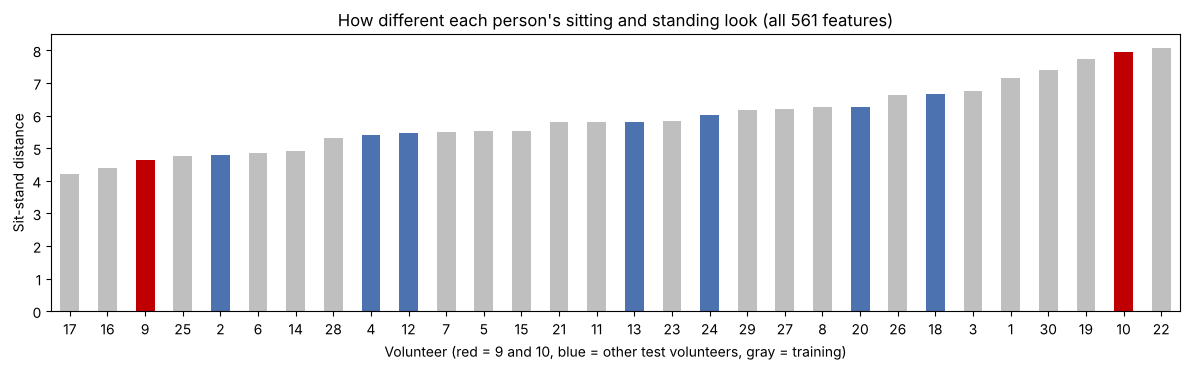

Volunteer 9 ranks 3 of 30 (1 = least separable); volunteer 10 ranks 29 of 30.


In [10]:
X_all = pd.concat([X_train, X_test], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)
s_all = pd.concat([subj_train, subj_test], ignore_index=True)
Z_all = StandardScaler().fit(X_train).transform(X_all)

gap = pd.Series({v: np.linalg.norm(Z_all[(s_all == v) & (y_all == 4)].mean(axis=0)
                                   - Z_all[(s_all == v) & (y_all == 5)].mean(axis=0))
                 for v in sorted(s_all.unique())}).sort_values()

colors = ["#C00000" if v in (9, 10) else ("#4C72B0" if v in set(subj_test) else "#BFBFBF")
          for v in gap.index]
ax = gap.plot.bar(figsize=(12, 3.8), color=colors, rot=0)
ax.set_xlabel("Volunteer (red = 9 and 10, blue = other test volunteers, gray = training)")
ax.set_ylabel("Sit-stand distance")
ax.set_title("How different each person's sitting and standing look (all 561 features)")
plt.tight_layout()
plt.show()
print(f"Volunteer 9 ranks {list(gap.index).index(9) + 1} of 30 (1 = least separable); "
      f"volunteer 10 ranks {list(gap.index).index(10) + 1} of 30.")

This confirms that the two volunteers struggle for **different reasons**:

- **Volunteer 9** is one of the people whose sitting and standing are least different overall,
  which makes errors more likely throughout. It is a risk factor, not a guarantee: test
  volunteer 2 is almost as low and still scored 98%, so how the two postures overlap matters,
  not just how far apart their averages are.
- **Volunteer 10** ranks among the *most* separable people on average. That figure is probably
  inflated somewhat by the unusual segment, which pulls the sitting average away from standing,
  but the perfectly classified first two sitting segments show that outside that run, this
  person's sitting and standing are easy to tell apart. Their errors come from one unusual
  period, not from a general similarity.

## 6. Upstairs mistaken for flat walking

Both volunteers had 7 upstairs windows labeled as flat walking. A simple check is how
vigorously the body moves, measured by the average magnitude of body acceleration.

In [11]:
MAG = "tBodyAccMag-mean()__201"
rows = {}
for vol in [9, 10]:
    rows[f"Vol {vol}"] = {SHORT[a]: X_test.loc[(subj_test.values == vol) & (y_test.values == a), MAG].median()
                          for a in (1, 2)}
rows["All training"] = {SHORT[a]: X_train.loc[y_train.values == a, MAG].median() for a in (1, 2)}
stairs = pd.DataFrame(rows).T
stairs["Upstairs minus Walk"] = stairs["Upstairs"] - stairs["Walk"]
stairs.style.format("{:.3f}").set_caption("Median body-acceleration magnitude (scaled units)")

,Walk,Upstairs,Upstairs minus Walk
Vol 9,-0.083,-0.266,-0.183
Vol 10,-0.130,-0.034,0.095
All training,-0.173,-0.094,0.079


For **volunteer 9**, climbing stairs is *less* vigorous than their flat walking (a negative
difference, the opposite of the typical pattern), which makes upstairs windows resemble walking.
For **volunteer 10**, this simple measure does not explain the errors, and their upstairs errors
are scattered rather than clustered. We do not have a clear explanation for those, and say so in
the report rather than guess.

## 7. Conclusions for the report

1. **Not a data shortage.** Volunteers 9 and 10 have about as many windows per activity as
   everyone else.
2. **Sitting vs. standing is the main cause** for both, but for different reasons:
   - **Volunteer 9:** their sitting and standing barely differ in phone orientation (3rd least
     separable of all 30 volunteers), so errors happen throughout, in both directions.
   - **Volunteer 10:** normally easy to classify, but during about 20 seconds of sitting the
     phone's tilt changed to a position unlike anything in the training data, and the model
     labeled that stretch as standing. This looks like a change in posture or phone position,
     not a general model failure.
3. **Upstairs vs. walking** adds a smaller share. For volunteer 9 it fits a gentle stair-climbing
   style; for volunteer 10 the cause is unclear.

**Implications (for Discussion / Limitations).**

- Accuracy figures depend heavily on how each person sits, stands, and wears the phone. With only
  9 test volunteers, a single unusual segment moves one person's accuracy by several points.
- Because the sitting/standing decision relies mostly on phone tilt, a phone that slips or is worn
  at an unfamiliar angle can cause long runs of errors, since the model cannot handle tilts it
  never saw in training. Possible remedies: features that do not
  depend on orientation, a short calibration period for each new user, or smoothing predictions
  over time (a 20-second run of "standing" in the middle of sitting is physically unlikely).
- Smoothing over time and per-user calibration are good **future work** ideas for the report.